![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
## Desafio 2
---

## 1. Contexto

Uma empresa tem uma sobra de caixa e, **no início de cada ano**, aplica **R$ 1.000 por 12 meses**. Há duas opções, as duas levadas até o vencimento:

* **Tesouro Selic:** rende a taxa Selic acumulada nos 12 meses
* **Tesouro IPCA+:** rende o IPCA acumulado nos 12 meses **mais uma taxa fixa de 5% ao ano**, contratada na compra

Qual rende mais depende de quanto a Selic e o IPCA vão ser nos 12 meses seguintes, e isso ninguém sabe na hora da compra. A equipe de tesouraria usa hoje uma regra simples: supor que a Selic e o IPCA dos próximos meses serão iguais aos do último mês (o **Naive**).

Você faz parte da equipe de análise de dados e vai **simular as decisões de 2021, 2022, 2023 e 2024**. No início de cada ano A, você usa só os dados **até dezembro do ano A-1** para escolher o ARIMA de cada série, projeta os 12 meses do ano A, calcula quanto cada investimento renderia e decide. Depois, confere o que realmente aconteceu. A pergunta é: **projetar a Selic e o IPCA com ARIMA leva a boas decisões?**

Nas Aulas 3 e 4, você viu:

* os modelos **AR, MA e ARMA** para séries estacionárias
* a **diferenciação** e o modelo **ARIMA(p, d, q)**
* como separar **treino, validação e teste** e medir o erro (MAE) contra um baseline
* como escolher a ordem com a **busca em grade**
* como prever com **intervalo de previsão**

## 2. Objetivo

Aplicar **busca em grade** e **ARIMA** para decidir, em cada ano de 2021 a 2024, entre o Tesouro Selic e o Tesouro IPCA+, e conferir a decisão com o que rendeu.

Você deverá:

1. Escolher a ordem (p, d, q) do ARIMA da Selic e do IPCA por **busca em grade**, só com os dados até 12/2020
2. Projetar os 12 meses de 2021, calcular o montante de cada investimento, decidir e conferir
3. Repetir o processo para cada ano de 2021 a 2024, com a grade refeita a cada ano, e comparar com o Naive
4. Escrever a conclusão

## 3. Dataset: Selic e IPCA mensais (Banco Central)

Os dados vêm do **Sistema Gerenciador de Séries Temporais (SGS)** do Banco Central do Brasil, uma API pública e gratuita. **Este enunciado já traz pronto** o download das séries, a tabela `df`, o gráfico e as funções que calculam o montante final: a sua parte começa na seção **Sua parte**, mais abaixo.

Características principais:

* **Selic mensal** (SGS 4390): taxa Selic acumulada no mês, em % ao mês
* **IPCA mensal** (SGS 433): variação mensal do índice oficial de inflação, em % ao mês
* **A tabela `df`:** uma linha por mês, de 01/2006 em diante, com as colunas `selic` e `ipca`

## 4. Escopo e limitações

Para manter o desafio focado no que vimos até aqui, valem estas regras. Elas também são **assunto da sua conclusão**.

1. O cenário é **fictício e simplificado**: sem imposto de renda, sem custos, sem marcação a mercado (o título é levado até o vencimento) e sem o atraso de divulgação do IPCA. A taxa fixa de 5% ao ano é definida por nós, e não é a taxa real de nenhum título
2. Use só as próprias séries, sem outras variáveis, e o ARIMA **sem sazonalidade**
3. O prazo é de **12 meses**, com uma compra **por ano**, em janeiro
4. A ordem (p, d, q) de **cada série** é escolhida por busca em grade, **só com os dados até dezembro do ano anterior** à compra: treino até dezembro do ano A-2 e validação durante o ano A-1. A grade é **refeita em cada ano**
5. **Isto não é recomendação de investimento nem prova de que o ARIMA prevê o mercado.** São apenas 4 decisões, e o resultado depende do cenário (a taxa fixa e o prazo). O objetivo é praticar a busca em grade e o ARIMA

## 5. Tarefas

Você deverá realizar as seguintes tarefas, na ordem. Tudo o que você precisa para resolvê-las está neste enunciado. Escreva a sua solução nas células abaixo do header **Sua parte**, no fim do notebook.

### 1. Escolher a ordem do ARIMA, só com dados até 12/2020

Primeiro, separe os dados até 12/2020, que são os únicos que podem ser usados para escolher a ordem em 2021. Guarde a posição de janeiro de 2021 na tabela (`i`) e a tabela com os dados anteriores a ela (`base`).

1. Escreva uma função `escolher_ordem(serie)` que recebe uma série, separa os **últimos 12 meses como validação** (aqui, o ano de 2020) e o resto como treino (até 12/2019), e ajusta a **grade** de ARIMA no treino, com $p$ e $q$ de 0 a 2 e $d$ igual a 0 ou 1. Cada ordem prevê os 12 meses da validação, e o erro é o MAE
2. A função devolve a ordem escolhida pela regra da Aula 4: vence o menor MAE; se o erro for parecido (até 10% acima do menor), vence o **mais simples**, ou seja, o de menor $p + q$ e, no empate, o de menor $d$. Se ainda houver empate, **escolha você o critério de desempate** e anote qual foi
3. Aplique a função à Selic (`base['selic']`) e ao IPCA (`base['ipca']`)
4. Para cada série, mostre a ordem escolhida e compare o MAE dela, na validação, com o do Naive (que repete o último valor do treino)

### 2. Projetar 2021 e decidir

1. Ajuste o ARIMA de cada série em `base`, com a ordem que você escolheu, e projete os 12 meses de 2021
2. Use as funções prontas (`montante_selic` e `montante_ipca_mais`) para calcular o **montante projetado** de R$ 1.000 em cada investimento, e **decida** pelo maior
3. Calcule o **montante realizado** de cada investimento em 2021, com as taxas reais (`df.iloc[i:i + H]`)
4. Mostre os quatro montantes, a decisão e se ela acertou (se escolheu o investimento que rendeu mais)
5. Plote, para a Selic e para o IPCA, o histórico recente, o valor real de 2021 e a projeção do ARIMA

### 3. Repetir para 2021, 2022, 2023 e 2024

1. Escreva uma função `decidir_ano(ano)` que faz as tarefas 1 e 2 para o ano recebido, **refazendo a grade com os dados só até dezembro do ano anterior**. Ela devolve um dicionário com o ano, a ordem escolhida para a Selic, a ordem escolhida para o IPCA, a decisão do ARIMA, a decisão do Naive, o investimento que realmente rendeu mais e os dois montantes realizados
2. A decisão do **Naive** usa as taxas do último mês do histórico (Selic e IPCA) repetidas pelos 12 meses e a mesma regra: escolher o maior montante
3. Aplique a função aos anos de `PRIMEIRO_ANO` a `ULTIMO_ANO`, monte uma tabela com uma linha por ano e mostre em quantos dos 4 anos o ARIMA, e em quantos o Naive, escolheu o investimento que rendeu mais

### 4. Conclusão

Em uma célula de texto, escreva uma conclusão curta, com:

1. O ARIMA decidiu bem? Em quantos dos 4 anos acertou, e quanto custou, em reais, cada erro
2. Qual **critério de desempate** você usou na escolha da ordem, e por quê
3. O ARIMA decidiu diferente do Naive? Em quais anos
4. As ordens escolhidas mudam de um ano para o outro? O que isso mostra sobre a busca em grade
5. As limitações: cenário fictício e simplificado, só 4 decisões, e o fato de que acertar a decisão não prova que o ARIMA prevê o mercado

> **Dicas:**
>
> * Os 12 meses realizados de um ano começam na posição do mês de janeiro dele na tabela. Descubra essa posição com o índice de datas e fatie os 12 meses seguintes
> * Na grade, trate os ajustes que falham (alguns não convergem) para que não interrompam o laço, e use o método de projeção do modelo ajustado para prever os 12 meses
> * A mesma função de grade serve para a Selic e para o IPCA: basta chamá-la duas vezes
> * As funções prontas recebem as **12 taxas** (em % ao mês) e devolvem o montante final em reais. Passe a projeção do ARIMA para obter o montante **projetado**, e as taxas reais para obter o **realizado**

## Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `urllib`, `io` e `time`: baixar o CSV da API e repetir a tentativa se ela falhar
* `statsmodels`: o modelo `ARIMA`
* `warnings`: ao ajustar muitos modelos, o `statsmodels` avisa sobre os valores iniciais dos parâmetros (`EstimationWarning`) e sobre convergência (`ConvergenceWarning`). Silenciamos só esses dois tipos de aviso, para a saída ficar limpa

In [1]:
import io
import time
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning

warnings.filterwarnings('ignore', category=EstimationWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

As constantes do cenário: o prazo `H` (em meses), a taxa fixa do IPCA+ (`TAXA_REAL`, em % ao ano) e os anos da simulação.

In [2]:
H = 12
TAXA_REAL = 5.0
PRIMEIRO_ANO = 2021
ULTIMO_ANO = 2024

## Os dados

A função que baixa uma série do Banco Central (a API às vezes devolve uma página de erro, então ela confere a resposta e tenta de novo) e a tabela `df` com a Selic e o IPCA mensais.

In [3]:
def baixar_sgs(codigo, tentativas=4):
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=csv&dataInicial=01/01/2006'
    pedido = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    for tentativa in range(tentativas):
        try:
            texto = urllib.request.urlopen(pedido, timeout=60).read().decode('utf-8')
            if texto.startswith('"data"'):
                break
        except Exception:
            pass
        time.sleep(3)
    else:
        raise RuntimeError(f'A API não devolveu a série {codigo}')
    tabela = pd.read_csv(io.StringIO(texto), sep=';', decimal=',')
    tabela.index = pd.to_datetime(tabela['data'], dayfirst=True)
    return tabela['valor'].astype(float)

In [4]:
selic = baixar_sgs(4390)
ipca = baixar_sgs(433)
df = pd.concat([selic, ipca], axis=1, keys=['selic', 'ipca']).dropna().asfreq('MS')
df.tail()

,selic,ipca
data,,
2026-05-01,1.07,0.58
2026-06-01,1.12,0.16
2026-07-01,1.22,0.07
2026-08-01,1.09,-0.32
2026-09-01,1.08,0.82


As duas séries. As duas estão em **% ao mês**.

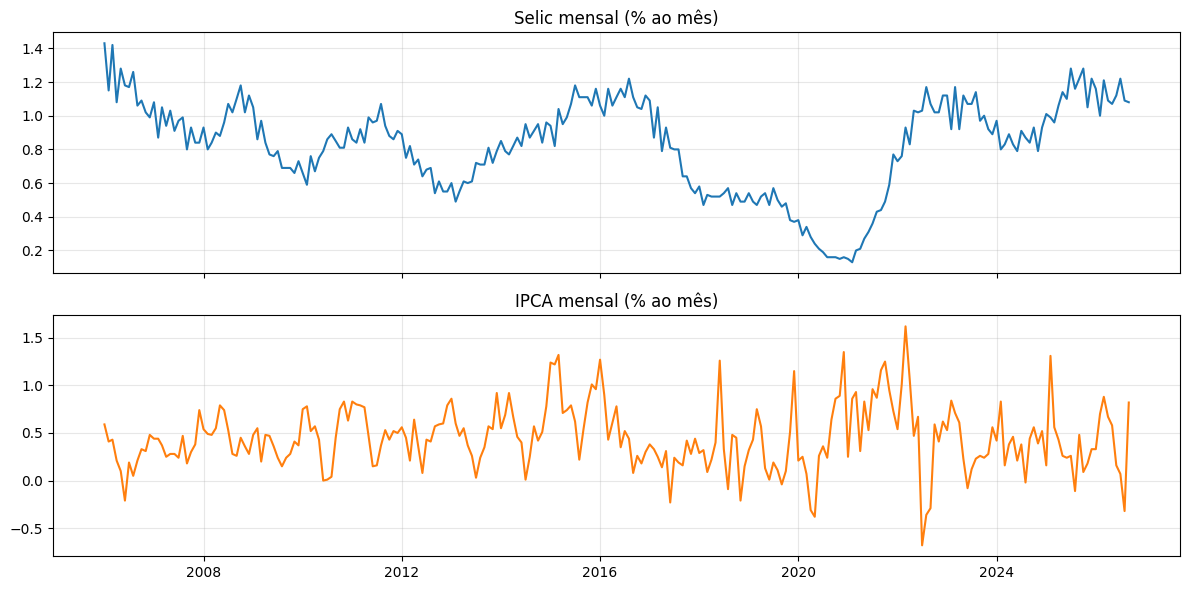

In [5]:
fig, eixos = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
eixos[0].plot(df.index, df['selic'], color='tab:blue')
eixos[0].set_title('Selic mensal (% ao mês)')
eixos[1].plot(df.index, df['ipca'], color='tab:orange')
eixos[1].set_title('IPCA mensal (% ao mês)')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Funções prontas: quanto rende em 12 meses

Duas funções recebem as **12 taxas mensais** (em %) e devolvem o **montante final**, em reais, de uma aplicação feita no início dos 12 meses (por padrão, R$ 1.000):

* `montante_selic(taxas)`: o Tesouro Selic
* `montante_ipca_mais(taxas_ipca)`: o Tesouro IPCA+, com a taxa fixa de 5% ao ano

Elas servem para as taxas **reais** (o que rendeu) e para as **projetadas** pelo ARIMA (o que se espera render).

In [6]:
def montante_selic(taxas, valor=1000):
    return valor * np.prod(1 + np.asarray(taxas) / 100)

def montante_ipca_mais(taxas_ipca, valor=1000, taxa_real=TAXA_REAL):
    return valor * np.prod(1 + np.asarray(taxas_ipca) / 100) * (1 + taxa_real / 100)

Um exemplo com as taxas reais do **primeiro ano** da tabela, de 01/2006 a 12/2006, e outro com uma Selic de 1% ao mês durante os 12 meses.

In [7]:
primeiro_ano = df.iloc[:12]
print('R$ 1.000 em 01/2006, por 12 meses | Tesouro Selic: R$', round(montante_selic(primeiro_ano['selic']), 2), '| Tesouro IPCA+: R$', round(montante_ipca_mais(primeiro_ano['ipca']), 2))
print('R$ 1.000 com a Selic a 1% ao mês por 12 meses: R$', round(montante_selic([1.0] * 12), 2))

R$ 1.000 em 01/2006, por 12 meses | Tesouro Selic: R$ 1150.81 | Tesouro IPCA+: R$ 1082.99
R$ 1.000 com a Selic a 1% ao mês por 12 meses: R$ 1126.83


---
# Solução